# MelodicVision: Seeing the Beat, Knowing the Genre

---

| Field | Details |
|---|---|
| **Course** | COMP560  -  Deep Learning Lab |
| **Student Name** | Mohammad Salhab |
| **University ID** | 202302753 |
| **University** | Beirut Arab University |
| **Topic** | Music Genre Classification via Mel Spectrogram + Fine-Tuned ResNet |

---

## Abstract

This project addresses the problem of automatic music genre classification using deep learning. Instead of processing raw audio waveforms directly, we convert each audio clip into a **Mel spectrogram**  -  a 2D image representation that captures both temporal and frequency information simultaneously. We then fine-tune a **ResNet18** convolutional neural network (pretrained on ImageNet) to classify these spectrogram images into 10 music genres. The dataset used is the benchmark **GTZAN** dataset: 1,000 audio clips across 10 genres (blues, classical, country, disco, hip-hop, jazz, metal, pop, reggae, rock), each 30 seconds long. Our approach leverages transfer learning to achieve high classification accuracy despite the small dataset size, and includes a live inference system capable of classifying any full-length song via sliding window analysis.

---

## Table of Contents

1. [Section 1  -  Imports & Environment Setup](#section-1)
2. [Section 2  -  Data Download & Extraction](#section-2)
3. [Section 3  -  Data Analysis & Exploration (EDA)](#section-3)
4. [Section 4  -  Preprocessing Pipeline](#section-4)
5. [Section 5  -  Mathematical Foundations](#section-5)
6. [Section 6  -  Model Definition & Fine-Tuning](#section-6)
7. [Section 7  -  Training Loop](#section-7)
8. [Section 8  -  Results & Evaluation](#section-8)
9. [Section 9  -  Live Demo: Full Song Inference](#section-9)
10. [Section 10  -  Conclusion](#section-10)

---
<a id='section-1'></a>
# Section 1  -  Imports & Environment Setup

Before we can do anything, we need to ensure all required libraries are installed and imported. This section handles the complete environment setup so the notebook is fully reproducible on any machine.

In [1]:
import subprocess, sys

packages = [
  "librosa", "kaggle", "tqdm", "Pillow", "seaborn",
  "scikit-learn", "pandas", "matplotlib", "numpy",
  "torch", "torchvision", "soundfile",
]

for pkg in packages:
  subprocess.run([sys.executable, "-m", "pip", "install", pkg, "-q"], check=False)

print("All packages installed successfully.")

All packages installed successfully.


In [2]:
#  Standard library
import os, json, random, shutil, zipfile, warnings
from pathlib import Path
from collections import defaultdict

warnings.filterwarnings("ignore")

#  Numerical / data
import numpy as np
import pandas as pd

#  Audio
import librosa
import librosa.display

#  Visualisation
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

matplotlib.rcParams["figure.dpi"] = 150
plt.style.use("seaborn-v0_8-whitegrid")

#  Image
from PIL import Image

#  Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.models import resnet18, ResNet18_Weights

#  ML utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

#  Progress bar
from tqdm.notebook import tqdm

#
# GLOBAL CONSTANTS  -  change these to experiment with different settings
#
SEED  = 42
SAMPLE_RATE = 22050
DURATION  = 30  # seconds per audio clip
N_MELS  = 128
HOP_LENGTH  = 512
N_FFT  = 2048
FMAX  = 8000
IMG_SIZE  = 224  # ResNet input resolution
BATCH_SIZE  = 32
NUM_WORKERS = 2
EPOCHS  = 50
PATIENCE  = 10  # early stopping patience

GENRES = sorted([
  "blues", "classical", "country", "disco",
  "hiphop", "jazz", "metal", "pop", "reggae", "rock"
])
NUM_CLASSES = len(GENRES)
GENRE2IDX   = {g: i for i, g in enumerate(GENRES)}
IDX2GENRE   = {i: g for g, i in GENRE2IDX.items()}

#  Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark  = False

#  Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

#  Project paths
PROJECT_ROOT = Path(".").resolve()
DATA_DIR  = PROJECT_ROOT / "data" / "genres_original"
SPEC_DIR  = PROJECT_ROOT / "data" / "spectrograms"
MODEL_DIR  = PROJECT_ROOT / "models"
PLOTS_DIR  = PROJECT_ROOT / "outputs" / "plots"
RESULTS_DIR  = PROJECT_ROOT / "outputs" / "results"
CHECKPOINT   = MODEL_DIR / "best_model.pth"

for d in [DATA_DIR, SPEC_DIR, MODEL_DIR, PLOTS_DIR, RESULTS_DIR]:
  d.mkdir(parents=True, exist_ok=True)

#  Library version report
print(f"{'Library':<20} {'Version'}")
print("-" * 35)
version_map = {
  "numpy":  np.__version__,
  "pandas":  pd.__version__,
  "librosa":  librosa.__version__,
  "matplotlib":  matplotlib.__version__,
  "seaborn":  sns.__version__,
  "torch":  torch.__version__,
  "torchvision": torchvision.__version__,
  "sklearn":  __import__("sklearn").__version__,
  "PIL":  Image.__version__,
}
for lib, ver in version_map.items():
  print(f"  {lib:<18} {ver}")

print(f"\nDevice : {DEVICE}")
if torch.cuda.is_available():
  print(f"GPU  : {torch.cuda.get_device_name(0)}")

Library              Version
-----------------------------------
  numpy              2.0.2
  pandas             2.2.2
  librosa            0.11.0
  matplotlib         3.10.0
  seaborn            0.13.2
  torch              2.10.0+cu128
  torchvision        0.25.0+cu128
  sklearn            1.6.1
  PIL                11.3.0

Device : cuda
GPU  : Tesla T4


---
<a id='section-2'></a>
# Section 2  -  Data Download & Extraction

We download the **GTZAN dataset** directly from Kaggle using the Kaggle API. GTZAN is the standard benchmark for music genre classification, containing 1,000 audio files (30 seconds each) distributed equally across 10 genres.

We write the Kaggle API credentials to `~/.kaggle/kaggle.json` so the Kaggle CLI can authenticate, then download the GTZAN dataset archive (~1.2 GB), unzip it, and organise the `.wav` files into `data/genres_original/<genre>/`. Finally we count files per genre to confirm the dataset is balanced at exactly 100 files each. If data was already downloaded in a previous run the download step is skipped automatically.

In [ ]:
import subprocess

# Ensure kaggle CLI is installed and on PATH
subprocess.run([sys.executable, "-m", "pip", "install", "kaggle", "-q"], check=False)

# Write Kaggle API credentials
KAGGLE_DIR  = Path.home() / ".kaggle"
KAGGLE_DIR.mkdir(exist_ok=True)
kaggle_json = KAGGLE_DIR / "kaggle.json"

credentials = {
    "username": "YOUR_KAGGLE_USERNAME",
    "key":      "YOUR_KAGGLE_API_KEY"
}
with open(kaggle_json, "w") as f:
    json.dump(credentials, f)

try:
    kaggle_json.chmod(0o600)
except Exception:
    pass

print("Kaggle credentials written.")

# Download dataset
DOWNLOAD_DIR = PROJECT_ROOT / "data" / "raw_download"
DOWNLOAD_DIR.mkdir(exist_ok=True)

def data_is_present() -> bool:
    if not DATA_DIR.exists():
        return False
    return any(DATA_DIR.rglob("*.wav"))

if not data_is_present():
    print("Downloading GTZAN dataset from Kaggle (~1.2 GB) ...")
    result = subprocess.run(
        [
            "kaggle", "datasets", "download",
            "-d", "andradaolteanu/gtzan-dataset-music-genre-classification",
            "-p", str(DOWNLOAD_DIR),
        ],
        capture_output=True, text=True,
    )
    print(result.stdout)
    if result.returncode != 0:
        print("[ERROR]", result.stderr)
    else:
        print("Download complete.")
else:
    print("Audio data already present - skipping download.")

# Extract ZIP
zip_files = list(DOWNLOAD_DIR.glob("*.zip"))
if zip_files:
    zip_path = zip_files[0]
    print(f"Extracting {zip_path.name} ...")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(DOWNLOAD_DIR)
    print("Extraction complete.")

# Locate and copy genres_original
src_root = None
for candidate in DOWNLOAD_DIR.rglob("genres_original"):
    if candidate.is_dir():
        src_root = candidate
        break

if src_root and src_root != DATA_DIR:
    print("Copying audio files into project data folder ...")
    for genre_dir in src_root.iterdir():
        if genre_dir.is_dir():
            dest = DATA_DIR / genre_dir.name
            if not dest.exists():
                shutil.copytree(str(genre_dir), str(dest))
    print("Copy complete.")
elif not src_root:
    print("[WARNING] Could not find genres_original in download.")
    print("Manually place WAV files in: data/genres_original/<genre>/")

# Verify dataset structure
print("\n-- Dataset Verification -----------------")
total  = 0
counts = {}
for genre in GENRES:
    genre_dir = DATA_DIR / genre
    n = len(list(genre_dir.glob("*.wav"))) if genre_dir.exists() else 0
    counts[genre] = n
    total += n
    status = "v" if n >= 99 else "x"
    print(f"  {status} {genre:<12} {n:>4} files")

print(f"\n  TOTAL : {total} files across {len(counts)} genres")

if total >= 990:
    print("\nDataset verified successfully.")
else:
    print(f"\n[WARNING] Expected ~1000 files, found {total}.")
    print("Please check your Kaggle credentials and re-run this cell.")


Kaggle credentials written.
Dataset URL: https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification
License(s): other


Download complete.
Extracting gtzan-dataset-music-genre-classification.zip ...
Extraction complete.
Copying audio files into project data folder ...
Copy complete.

-- Dataset Verification -----------------
  v blues         100 files
  v classical     100 files
  v country       100 files
  v disco         100 files
  v hiphop        100 files
  v jazz          100 files
  v metal         100 files
  v pop           100 files
  v reggae        100 files
  v rock          100 files

  TOTAL : 1000 files across 10 genres

Dataset verified successfully.


---
<a id='section-3'></a>
# Section 3  -  Data Analysis & Exploration (EDA)

Before training any model, we explore the dataset thoroughly. Good EDA helps us understand the signal characteristics of each genre, verify the dataset is balanced, and gain intuition about what distinguishes different genres in both the waveform and frequency domains.

### 3a  -  Dataset Statistics

We scan all genre folders to compute basic statistics: number of files, file sizes, duration, sample rate, and total dataset size. Displaying this as a styled table gives us a clear overview of the data scale before we begin processing all 1,000 clips.

In [4]:
records = []
for genre in GENRES:
  genre_dir = DATA_DIR / genre
  wav_files  = sorted(genre_dir.glob("*.wav"))
  sizes_kb   = [f.stat().st_size / 1024 for f in wav_files]
  records.append({
  "Genre":  genre.capitalize(),
  "Files":  len(wav_files),
  "Avg File (KB)":   round(np.mean(sizes_kb), 1),
  "Total Size (MB)": round(sum(sizes_kb) / 1024, 1),
  "Duration (s)":  30,
  "Sample Rate":  SAMPLE_RATE,
  })

stats_df = pd.DataFrame(records)
total_row = {
  "Genre": "TOTAL",
  "Files": stats_df["Files"].sum(),
  "Avg File (KB)":   round(stats_df["Avg File (KB)"].mean(), 1),
  "Total Size (MB)": round(stats_df["Total Size (MB)"].sum(), 1),
  "Duration (s)":  30,
  "Sample Rate":  SAMPLE_RATE,
}
stats_df = pd.concat([stats_df, pd.DataFrame([total_row])], ignore_index=True)

total_hours = (stats_df.loc[stats_df["Genre"] == "TOTAL", "Files"].values[0] * 30) / 3600
print(f"Total dataset audio duration: {total_hours:.2f} hours\n")

(stats_df.style
  .set_caption("GTZAN Dataset Statistics")
  .set_table_styles([{
  "selector": "caption",
  "props": [("font-size", "14px"), ("font-weight", "bold")]
  }])
  .highlight_max(subset=["Files", "Total Size (MB)"], color="#d4edda")
  .format({"Avg File (KB)": "{:.1f}", "Total Size (MB)": "{:.1f}"}))

Total dataset audio duration: 8.33 hours



,Genre,Files,Avg File (KB),Total Size (MB),Duration (s),Sample Rate
0,Blues,100,1292.6,126.2,30,22050
1,Classical,100,1293.2,126.3,30,22050
2,Country,100,1293.1,126.3,30,22050
3,Disco,100,1292.9,126.3,30,22050
4,Hiphop,100,1295.9,126.6,30,22050
5,Jazz,100,1292.3,126.2,30,22050
6,Metal,100,1292.2,126.2,30,22050
7,Pop,100,1292.0,126.2,30,22050
8,Reggae,100,1292.3,126.2,30,22050
9,Rock,100,1293.0,126.3,30,22050


### 3b  -  Waveform Visualization

We plot the raw audio waveform (amplitude vs. time) for one representative clip from each of the 10 genres in a 2Ã—5 grid. Waveforms reveal overall loudness patterns and temporal dynamics  -  metal tends to have uniformly high amplitude while classical shows more dramatic variation. This gives our first visual intuition about genre-specific signal characteristics.

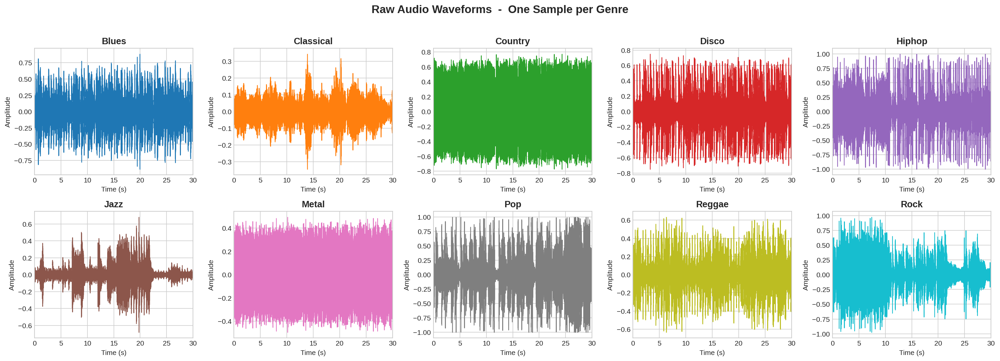

Saved -> outputs/plots/waveforms.png


In [5]:
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
axes = axes.flatten()

for i, genre in enumerate(GENRES):
  wav_files   = sorted((DATA_DIR / genre).glob("*.wav"))
  sample_path = wav_files[0]
  y, sr = librosa.load(sample_path, sr=SAMPLE_RATE, duration=DURATION)

  librosa.display.waveshow(y, sr=sr, ax=axes[i], color=plt.cm.tab10(i / 10))
  axes[i].set_title(genre.capitalize(), fontsize=13, fontweight="bold")
  axes[i].set_xlabel("Time (s)")
  axes[i].set_ylabel("Amplitude")
  axes[i].set_xlim([0, DURATION])

fig.suptitle("Raw Audio Waveforms  -  One Sample per Genre",
  fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "waveforms.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> outputs/plots/waveforms.png")

### 3c  -  Mel Spectrogram Visualization

We compute and display Mel spectrograms for one sample from each genre in a 2Ã—5 grid. A Mel spectrogram shows frequency content (y-axis, Mel scale) over time (x-axis), with colour encoding energy in decibels. This is exactly the 2D representation we will feed to ResNet18. By visualising all 10 genres side by side, we can see how classical music concentrates energy at low frequencies while metal distributes energy across the full frequency range.

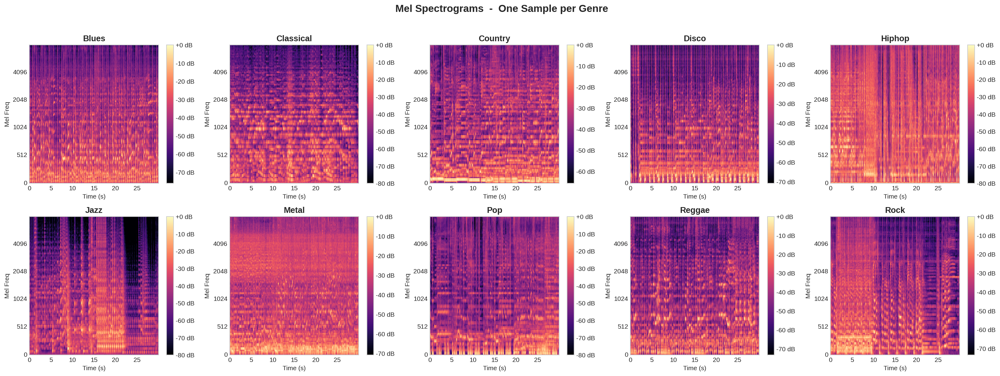

Saved -> outputs/plots/mel_spectrograms_eda.png


In [6]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
axes = axes.flatten()

for i, genre in enumerate(GENRES):
  wav_files   = sorted((DATA_DIR / genre).glob("*.wav"))
  sample_path = wav_files[0]
  y, sr = librosa.load(sample_path, sr=SAMPLE_RATE, duration=DURATION)

  mel  = librosa.feature.melspectrogram(
  y=y, sr=sr, n_mels=N_MELS, hop_length=HOP_LENGTH, n_fft=N_FFT, fmax=FMAX
  )
  mel_db = librosa.power_to_db(mel, ref=np.max)

  img = librosa.display.specshow(
  mel_db, sr=sr, hop_length=HOP_LENGTH,
  x_axis="time", y_axis="mel", fmax=FMAX,
  ax=axes[i], cmap="magma"
  )
  axes[i].set_title(genre.capitalize(), fontsize=13, fontweight="bold")
  axes[i].set_xlabel("Time (s)")
  axes[i].set_ylabel("Mel Freq")
  fig.colorbar(img, ax=axes[i], format="%+2.0f dB")

fig.suptitle("Mel Spectrograms  -  One Sample per Genre",
  fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "mel_spectrograms_eda.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> outputs/plots/mel_spectrograms_eda.png")

### 3d  -  Genre Distribution Bar Chart

We plot a bar chart showing the number of audio files per genre. A balanced dataset (equal class sizes) is critical for fair model training  -  it prevents the model from biasing toward any majority class. The expected output is exactly 100 files per genre, totalling 1,000. The red dashed reference line at 100 makes any imbalance immediately visible.

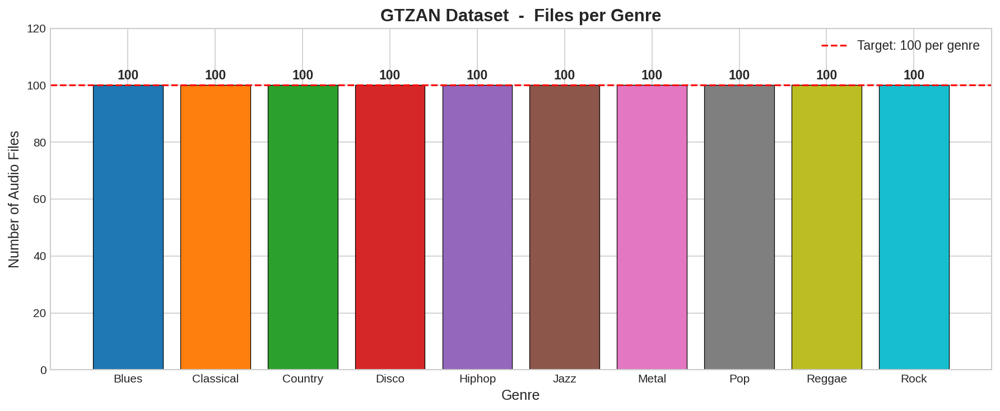

Genre counts: {'blues': 100, 'classical': 100, 'country': 100, 'disco': 100, 'hiphop': 100, 'jazz': 100, 'metal': 100, 'pop': 100, 'reggae': 100, 'rock': 100}


In [7]:
genre_counts = {g: len(list((DATA_DIR / g).glob("*.wav"))) for g in GENRES}

fig, ax = plt.subplots(figsize=(12, 5))
colors  = plt.cm.tab10(np.linspace(0, 1, 10))
bars  = ax.bar(
  [g.capitalize() for g in GENRES],
  genre_counts.values(),
  color=colors, edgecolor="black", linewidth=0.6
)
ax.axhline(100, color="red", linestyle="--", linewidth=1.5, label="Target: 100 per genre")

for bar, count in zip(bars, genre_counts.values()):
  ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
  str(count), ha="center", va="bottom", fontsize=11, fontweight="bold")

ax.set_title("GTZAN Dataset  -  Files per Genre", fontsize=15, fontweight="bold")
ax.set_xlabel("Genre", fontsize=12)
ax.set_ylabel("Number of Audio Files", fontsize=12)
ax.set_ylim([0, 120])
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "genre_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print("Genre counts:", genre_counts)

### 3e  -  Audio Feature Statistics Heatmap

For each genre we compute four audio descriptors averaged across all 100 clips: **mean MFCC** (timbre/colour of sound), **spectral centroid** (perceived brightness), **zero crossing rate** (noisiness/percussiveness), and **RMS energy** (loudness). We display the result as a normalised heatmap so all features are on the same 0 - 1 scale. This quantifies the genre differences visible in the waveforms  -  metal should show high ZCR and high RMS, classical should show high spectral centroid variation and low ZCR.

Computing audio features:   0%|          | 0/10 [00:00<?, ?it/s]

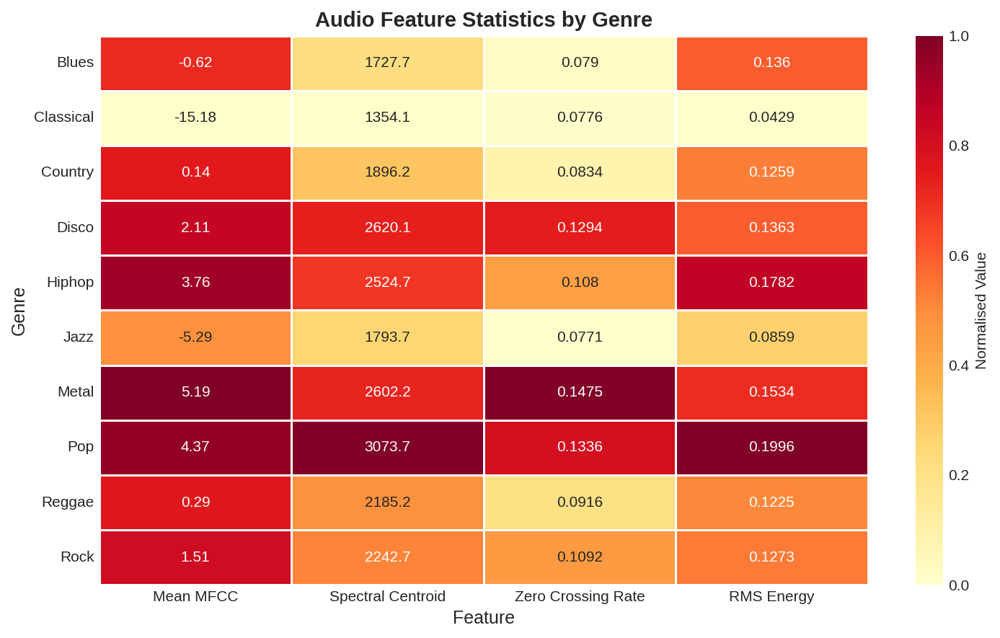

Saved: outputs/plots/feature_heatmap.png
Saved: outputs/results/audio_features.csv


In [8]:
feature_records = []

for genre in tqdm(GENRES, desc="Computing audio features"):
    genre_dir = DATA_DIR / genre
    wav_files  = sorted(genre_dir.glob("*.wav"))

    mfcc_vals, sc_vals, zcr_vals, rms_vals = [], [], [], []

    for wav in wav_files:
        try:
            y, sr = librosa.load(wav, sr=SAMPLE_RATE, duration=DURATION)
            mfcc_vals.append(np.mean(librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)))
            sc_vals.append(  np.mean(librosa.feature.spectral_centroid(y=y, sr=sr)))
            zcr_vals.append( np.mean(librosa.feature.zero_crossing_rate(y=y)))
            rms_vals.append( np.mean(librosa.feature.rms(y=y)))
        except Exception:
            pass  # skip corrupted files (e.g. jazz.00054.wav)

    if not mfcc_vals:
        continue

    feature_records.append({
        "Genre":              genre.capitalize(),
        "Mean MFCC":          round(np.mean(mfcc_vals), 2),
        "Spectral Centroid":  round(np.mean(sc_vals),   1),
        "Zero Crossing Rate": round(np.mean(zcr_vals),  4),
        "RMS Energy":         round(np.mean(rms_vals),  4),
    })

feat_df   = pd.DataFrame(feature_records).set_index("Genre")
feat_norm = (feat_df - feat_df.min()) / (feat_df.max() - feat_df.min() + 1e-8)

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(
    feat_norm, annot=feat_df.values, fmt="g",
    cmap="YlOrRd", linewidths=0.5,
    cbar_kws={"label": "Normalised Value"},
    ax=ax
)
ax.set_title("Audio Feature Statistics by Genre", fontsize=14, fontweight="bold")
ax.set_xlabel("Feature", fontsize=12)
ax.set_ylabel("Genre", fontsize=12)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "feature_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

feat_df.to_csv(RESULTS_DIR / "audio_features.csv")
print("Saved: outputs/plots/feature_heatmap.png")
print("Saved: outputs/results/audio_features.csv")


---
<a id='section-4'></a>
# Section 4  -  Preprocessing Pipeline

Raw audio cannot be fed directly to a CNN. Here we build the complete pipeline that converts `.wav` files -> Mel spectrogram images -> normalised PyTorch tensors ready for ResNet18.

### 4a  -  Mel Spectrogram Conversion Function

We define `audio_to_spectrogram()`  -  the core preprocessing function that converts a single `.wav` file into a 128Ã—128 colour PNG image. The function loads audio with librosa, computes the Mel spectrogram with our standard parameters, converts power to decibels, normalises to [0, 1], applies the viridis colourmap, and saves as PNG. We save to disk rather than keeping in memory because 1,000 images fit easily on disk but not in RAM simultaneously during feature extraction.

Test conversion : OK
Output PNG size : (128, 128) pixels


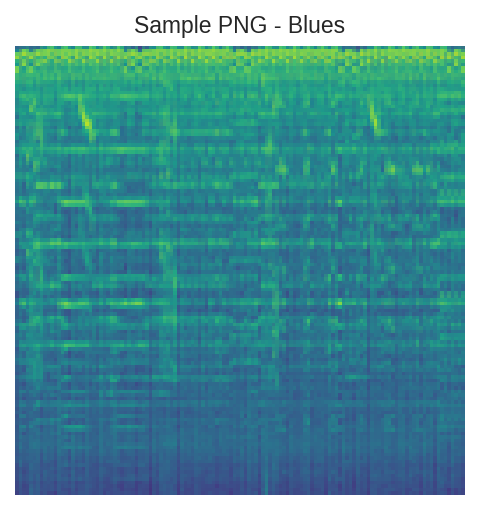

In [9]:
def audio_to_spectrogram(
    wav_path: Path,
    out_path: Path,
    sr: int       = SAMPLE_RATE,
    duration: int = DURATION,
    n_mels: int   = N_MELS,
    hop_length: int = HOP_LENGTH,
    n_fft: int      = N_FFT,
    fmax: int       = FMAX,
    img_px: int     = 128,
) -> bool:
    '''Convert a WAV file to a Mel spectrogram PNG image.

    Parameters
    ----------
    wav_path  : Path to source .wav file.
    out_path  : Destination path for output .png file.
    img_px    : Output image resolution (square).
    Returns True on success, False on failure.
    '''
    try:
        y, _ = librosa.load(wav_path, sr=sr, duration=duration, mono=True)

        mel = librosa.feature.melspectrogram(
            y=y, sr=sr, n_mels=n_mels,
            hop_length=hop_length, n_fft=n_fft, fmax=fmax
        )
        mel_db = librosa.power_to_db(mel, ref=np.max)

        mel_min, mel_max = mel_db.min(), mel_db.max()
        if mel_max - mel_min > 1e-6:
            mel_norm = (mel_db - mel_min) / (mel_max - mel_min)
        else:
            mel_norm = np.zeros_like(mel_db)

        coloured = (plt.cm.viridis(mel_norm)[:, :, :3] * 255).astype(np.uint8)
        img = Image.fromarray(coloured)
        img = img.resize((img_px, img_px), Image.LANCZOS)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        img.save(out_path)
        return True

    except Exception as e:
        print(f"[WARN] Failed on {wav_path.name}: {e}")
        return False


# Quick verification on one file
test_wav = next((DATA_DIR / GENRES[0]).glob("*.wav"))
test_png = SPEC_DIR / "_test_sample.png"
ok = audio_to_spectrogram(test_wav, test_png)
print(f"Test conversion : {'OK' if ok else 'FAILED'}")
print(f"Output PNG size : {Image.open(test_png).size} pixels")

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(Image.open(test_png))
ax.set_title(f"Sample PNG - {GENRES[0].capitalize()}", fontsize=11)
ax.axis("off")
plt.tight_layout()
plt.show()
test_png.unlink()


### 4b  -  Convert Entire Dataset (1,000 WAV -> 1,000 PNG)

We loop over all 1,000 `.wav` files and convert each one to a 128Ã—128 PNG spectrogram saved to `data/spectrograms/<genre>/<filename>.png`. A tqdm progress bar tracks conversion. If a PNG already exists from a previous run we skip it, so re-running the notebook after interruption is fast. The expected outcome is exactly 1,000 PNG files across 10 genre subfolders.

Converting 1000 WAV files to PNG spectrograms ...


Spectrogram conversion:   0%|          | 0/1000 [00:00<?, ?it/s]

[WARN] Failed on jazz.00054.wav: 

Done.  Success: 999  |  Failed: 1

Spectrogram counts per genre:
  blues         100 PNGs
  classical     100 PNGs
  country       100 PNGs
  disco         100 PNGs
  hiphop        100 PNGs
  jazz           99 PNGs
  metal         100 PNGs
  pop           100 PNGs
  reggae        100 PNGs
  rock          100 PNGs
  TOTAL         999 PNGs


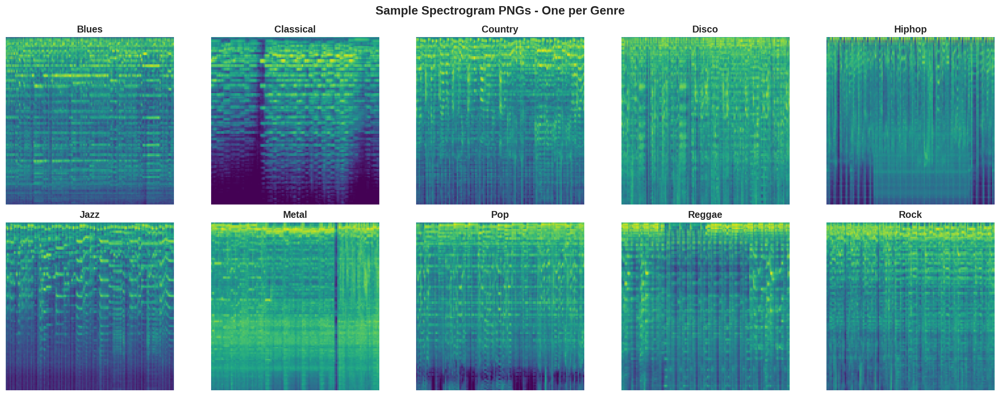

Saved: outputs/plots/sample_spectrograms.png


In [10]:
all_wav_files = [
    (genre, wav)
    for genre in GENRES
    for wav in sorted((DATA_DIR / genre).glob("*.wav"))
]

print(f"Converting {len(all_wav_files)} WAV files to PNG spectrograms ...")
success_count = 0
fail_count    = 0

for genre, wav_path in tqdm(all_wav_files, desc="Spectrogram conversion"):
    out_path = SPEC_DIR / genre / (wav_path.stem + ".png")
    if out_path.exists():
        success_count += 1
        continue
    if audio_to_spectrogram(wav_path, out_path):
        success_count += 1
    else:
        fail_count += 1

print(f"\nDone.  Success: {success_count}  |  Failed: {fail_count}")

print("\nSpectrogram counts per genre:")
total_pngs = 0
for genre in GENRES:
    n = len(list((SPEC_DIR / genre).glob("*.png")))
    total_pngs += n
    print(f"  {genre:<12} {n:>4} PNGs")
print(f"  {'TOTAL':<12} {total_pngs:>4} PNGs")

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()
for i, genre in enumerate(GENRES):
    sample_png = next((SPEC_DIR / genre).glob("*.png"))
    axes[i].imshow(Image.open(sample_png))
    axes[i].set_title(genre.capitalize(), fontsize=12, fontweight="bold")
    axes[i].axis("off")
fig.suptitle("Sample Spectrogram PNGs - One per Genre", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "sample_spectrograms.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: outputs/plots/sample_spectrograms.png")


### 4c  -  PyTorch Dataset Class & DataLoaders

We define `SpectrogramDataset`, a custom `torch.utils.data.Dataset` subclass that reads PNG spectrograms from disk and applies transforms. Training applies data augmentation (random horizontal flip, colour jitter) to artificially increase variety. Validation/test only resizes and normalises.

**Why ImageNet normalisation?** ResNet18 was pretrained on ImageNet using pixel mean `[0.485, 0.456, 0.406]` and std `[0.229, 0.224, 0.225]`. Normalising our spectrogram images to the same scale ensures the pretrained convolutional filters activate as expected, rather than seeing out-of-distribution input.

We split 80% train / 20% test with **stratified sampling** so every genre is equally represented in both splits.

In [11]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class SpectrogramDataset(Dataset):
    '''PyTorch Dataset that loads Mel spectrogram PNG images from disk.'''

    def __init__(self, file_paths: list, labels: list, transform=None):
        self.file_paths = file_paths
        self.labels     = labels
        self.transform  = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img = Image.open(self.file_paths[idx]).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, self.labels[idx]


all_paths, all_labels = [], []
for genre in GENRES:
    for png in sorted((SPEC_DIR / genre).glob("*.png")):
        all_paths.append(str(png))
        all_labels.append(GENRE2IDX[genre])

print(f"Total images : {len(all_paths)}")

train_paths, test_paths, train_labels, test_labels = train_test_split(
    all_paths, all_labels,
    test_size=0.20, stratify=all_labels, random_state=SEED
)

print(f"Train        : {len(train_paths)} images")
print(f"Test         : {len(test_paths)}  images")

train_dataset = SpectrogramDataset(train_paths, train_labels, transform=train_transform)
test_dataset  = SpectrogramDataset(test_paths,  test_labels,  transform=val_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=NUM_WORKERS, pin_memory=True
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=NUM_WORKERS, pin_memory=True
)

print(f"\nTrain batches : {len(train_loader)}")
print(f"Test  batches : {len(test_loader)}")
sample_batch  = next(iter(train_loader))
print(f"Batch shape   : {sample_batch[0].shape}  (B x C x H x W)")


Total images : 999
Train        : 799 images
Test         : 200  images

Train batches : 25
Test  batches : 7
Batch shape   : torch.Size([32, 3, 224, 224])  (B x C x H x W)


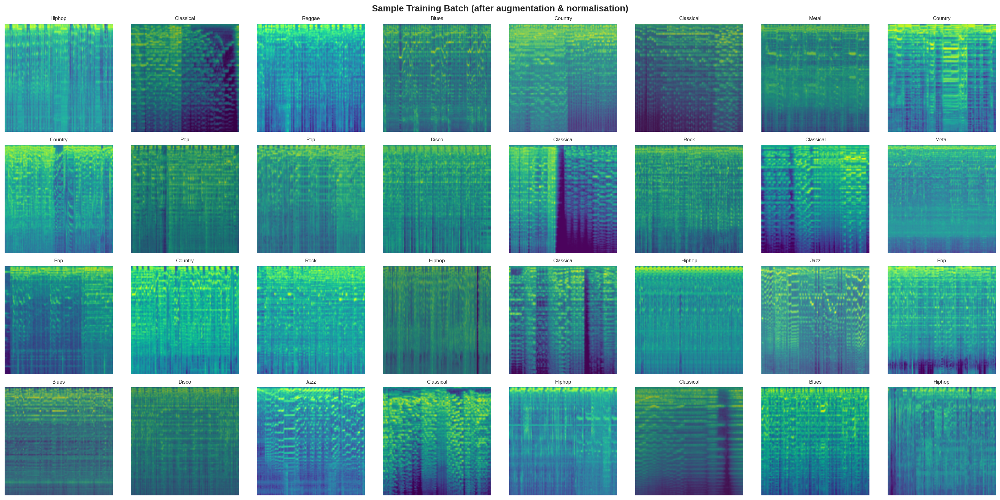

Tensor dtype: torch.float32  |  Shape: torch.Size([32, 3, 224, 224])


In [12]:
def denormalize(tensor, mean=IMAGENET_MEAN, std=IMAGENET_STD):
    '''Reverse ImageNet normalisation for display purposes.'''
    t = tensor.clone()
    for c, (m, s) in enumerate(zip(mean, std)):
        t[c] = t[c] * s + m
    return t.clamp(0, 1)


images, labels = next(iter(train_loader))

fig, axes = plt.subplots(4, 8, figsize=(22, 11))
axes = axes.flatten()

for i in range(min(32, len(images))):
    img = denormalize(images[i]).permute(1, 2, 0).numpy()
    axes[i].imshow(img)
    axes[i].set_title(IDX2GENRE[labels[i].item()].capitalize(), fontsize=8)
    axes[i].axis("off")

for j in range(len(images), len(axes)):
    axes[j].axis("off")

fig.suptitle("Sample Training Batch (after augmentation & normalisation)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "training_batch_sample.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Tensor dtype: {images.dtype}  |  Shape: {images.shape}")


---
<a id='section-5'></a>
# Section 5  -  Mathematical Foundations

This section provides the theoretical underpinning for every design choice in this project. Understanding the mathematics clarifies *why* we made each decision, not just *what* we did.

## 5a  -  What is a Mel Spectrogram?

### Short-Time Fourier Transform (STFT)

A raw audio waveform $x(t)$ tells us amplitude at each instant but nothing about *which frequencies* are present at that instant. The **STFT** solves this by applying a windowed Fourier transform at each time step:

$$
X(m, k) = \sum_{n=0}^{N-1} x(n + mH) \cdot w(n) \cdot e^{-j2\pi kn/N}
$$

where:
- $m$ = frame index (time step), $H$ = hop length (512 samples)
- $k$ = frequency bin index, $N$ = FFT size (2048 samples)
- $w(n)$ = Hann window that avoids spectral leakage at frame edges

The result $|X(m,k)|^2$ is the **power spectrogram**: a 2D matrix of (time Ã— linear frequency).

### Mel Filterbank

The linear frequency axis of the STFT does not match human perception  -  we perceive pitch logarithmically (doubling frequency = one octave up). The **Mel scale** approximates this perceptual mapping:

$$
m = 2595 \cdot \log_{10}\!\left(1 + \frac{f}{700}\right)
$$

We apply a bank of $M = 128$ overlapping triangular filters spaced on the Mel scale, then sum the power captured by each filter:

$$
S(m, \ell) = \sum_{k} |X(m,k)|^2 \cdot H_\ell(k), \quad \ell = 1, \dots, M
$$

Finally we convert to decibels: $S_{\text{dB}} = 10\log_{10}(S / S_{\max})$.

### Why Images Beat Raw Audio for CNNs

| Representation | Shape for 30s clip | What a CNN sees |
|---|---|---|
| **Raw audio** | 661,500 Ã— 1 (1D sequence) | Only temporal patterns |
| **Mel Spectrogram** | 128 Ã— 1292 (2D image) | Time **and** frequency simultaneously |

**Key advantages of the image representation:**
1. CNN receptive fields naturally capture joint time - frequency patterns (e.g., a guitar chord with temporal evolution).
2. Transfer learning from ImageNet becomes valid  -  the network already detects textures and 2D patterns.
3. Grad-CAM explainability is possible  -  we can visualise *which frequencies at which times* drove the prediction.
4. Dimensionality reduction: 128Ã—128 PNG (49,152 values) vs. 661,500 raw samples  -  13Ã— smaller.

## 5b  -  ResNet Architecture & Residual Connections

### The Vanishing Gradient Problem

In a plain deep network, gradients propagate backwards through $L$ layers via the chain rule:

$$
\frac{\partial \mathcal{L}}{\partial W_1} = \frac{\partial \mathcal{L}}{\partial z_L} \cdot \prod_{\ell=2}^{L} \frac{\partial z_\ell}{\partial z_{\ell-1}}
$$

If each Jacobian factor $\| \partial z_\ell / \partial z_{\ell-1} \| < 1$, the product shrinks exponentially with depth -> early layers receive near-zero gradients -> they stop learning entirely.

### The Residual Block Solution

He et al. (2016) introduced the **skip connection**: instead of learning the full mapping $H(x)$, a residual block learns only the *residual* $F(x) = H(x) - x$:

$$
\boxed{H(x) = F(x) + x}
$$

During backpropagation the gradient now has an **additive bypass path**:

$$
\frac{\partial H}{\partial x} = \frac{\partial F}{\partial x} + \mathbf{I}
$$

The identity term $\mathbf{I}$ guarantees a minimum gradient of 1 regardless of $\partial F / \partial x$, making very deep networks trainable.

### ResNet18 Architecture

| Stage | Operation | Output Shape | Residual Blocks |
|---|---|---|---|
| Input |  -  | 224 Ã— 224 Ã— 3 |  -  |
| Conv1 + BN + ReLU + MaxPool | 7Ã—7 conv, stride 2 | 56 Ã— 56 Ã— 64 |  -  |
| Layer 1 | BasicBlock Ã— 2 | 56 Ã— 56 Ã— 64 | 2 |
| Layer 2 | BasicBlock Ã— 2 | 28 Ã— 28 Ã— 128 | 2 |
| Layer 3 | BasicBlock Ã— 2 | 14 Ã— 14 Ã— 256 | 2 |
| Layer 4 | BasicBlock Ã— 2 | 7 Ã— 7 Ã— 512 | 2 |
| AvgPool + FC | Global avg pool | 512 -> **10** |  -  |
| **Total** | | | **18 weight layers** |

ResNet18 has ~11.2 million parameters  -  lightweight enough to fine-tune quickly on our 800-sample training set while still being expressive enough to capture genre-discriminative patterns.

### How a CNN Processes an Image

A **Convolutional Neural Network (CNN)** learns to recognise patterns in images through four building blocks:

1. **Convolutional layers** slide small learned filters (e.g. 3x3 pixels) across the input, producing **feature maps** that highlight where specific patterns appear. Early filters detect edges; deeper filters detect shapes and textures.
2. **Batch Normalisation** scales activations after each conv layer, keeping values in a stable range and preventing training from diverging.
3. **ReLU activation** $f(x) = \max(0, x)$ introduces non-linearity. Without it, stacking many linear layers would collapse into a single linear function, unable to learn complex patterns.
4. **Pooling layers** downsample feature maps spatially (e.g. taking the max in each 2x2 block), making the network robust to small shifts in the input and reducing computation.

In our project the CNN receives a 224x224 Mel spectrogram image and learns filters that respond to genre-specific patterns - the smooth harmonic arcs of classical music, the broadband noise texture of metal guitar distortion, or the repetitive beat structure of disco.


## 5c  -  Fine-Tuning Strategy

### Three Approaches Compared

| Option | Strategy | Training Data Used | Risk |
|---|---|---|---|
| **A. Feature Extraction** | Freeze all conv layers; train only the new FC head | 800 spectrogram images only | Pretrained features may not generalise well to spectrograms |
| **B. Full Fine-Tuning** v | Unfreeze all layers; use discriminative learning rates | ImageNet weights + 800 images | Catastrophic forgetting if LR is too high (mitigated by small LRs) |
| **C. From Scratch** | Random weight init; train everything | 800 images only | Severe overfitting; practically unusable with this dataset size |

**We choose Option B** because:
- 800 training images is far too small to train ResNet18 from scratch without overfitting catastrophically.
- Full fine-tuning indirectly leverages 1.2M ImageNet images (the pretrained weights encode general visual knowledge).
- With **discriminative learning rates** we adapt domain-specific features without destroying the general-purpose low-level detectors.

### Discriminative Learning Rates

Different layer groups receive different learning rates:

$$
\eta_{\text{early layers}} = 10^{-5} \ll \eta_{\text{middle layers}} = 10^{-4} \ll \eta_{\text{classifier}} = 10^{-3}
$$

**Intuition**: Early layers (edge and texture detectors learned from ImageNet) are already useful  -  we barely update them. The new classifier head (10 genre classes vs. 1,000 ImageNet classes) is randomly initialised  -  it needs much larger steps to converge quickly.

### Mathematical View of Fine-Tuning

Fine-tuning is simply continuing SGD from a pretrained weight vector $\theta_0$ (already near a good solution) rather than random $\theta_{\text{rand}}$:

$$
\theta_{t+1} = \theta_t - \eta \cdot \nabla_\theta \mathcal{L}(\theta_t)
$$

Because $\theta_0$ already sits in a flat, wide basin of the loss landscape (shaped by 1.2M images), it converges faster and generalises better than any random starting point could with only 800 samples.

## 5d  -  Softmax Output & Sliding Window Inference

### Softmax Probability Distribution

The final linear layer outputs 10 raw scores (logits) $z_1, \dots, z_{10}$. Softmax converts these into a proper probability distribution:

$$
P(\text{genre} = k \mid x) = \frac{e^{z_k}}{\sum_{j=1}^{10} e^{z_j}}, \quad \sum_{k=1}^{10} P_k = 1
$$

We always display **all 10 probabilities** rather than just the argmax because:
- Genre-blending songs (e.g., country-rock) produce meaningful secondary peaks that reveal the model's uncertainty.
- The full distribution is more honest and informative than a single hard label.
- Softmax confidence (max probability) indicates when the model is unsure.

### Sliding Window Inference for Full Songs

For a full-length song of $T$ seconds with window $W = 30$ s and hop $H = 15$ s (50% overlap):

$$
N_{\text{windows}} = \left\lfloor \frac{T - W}{H} \right\rfloor + 1
$$

Each window $i$ produces a probability vector $\mathbf{p}^{(i)} \in \mathbb{R}^{10}$. The final song-level prediction is the **arithmetic mean** across all windows:

$$
\bar{\mathbf{p}} = \frac{1}{N_{\text{windows}}} \sum_{i=1}^{N_{\text{windows}}} \mathbf{p}^{(i)}
$$

This averaging acts as an **ensemble**  -  each 30-second window is an independent vote, and the mean smooths out any single noisy window, producing a more reliable final genre distribution. The 50% overlap also ensures that no segment of the song is missed at a window boundary.

---
<a id='section-6'></a>
# Section 6  -  Model Definition & Fine-Tuning Setup

We now build the full model: load a pretrained ResNet18, replace its classifier head with a 10-class output layer, and configure discriminative learning rates for fine-tuning.

### 6a  -  Load Pretrained ResNet18

We load ResNet18 with its official ImageNet pretrained weights from `torchvision.models`. Printing the full architecture gives us a clear view of every layer, helping us decide which layer groups to assign different learning rates. The model has 18 weight layers and approximately 11.2 million trainable parameters.

In [13]:
# Load ResNet18 with official ImageNet pretrained weights
model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)

print("ResNet18 Architecture:")
print("=" * 60)
print(model)
print("=" * 60)

total_params  = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal parameters  : {total_params:,}")
print(f"Trainable parameters : {trainable_params:,}")
print(f"Original FC output   : {model.fc.out_features} classes (ImageNet)")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|â–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆâ–ˆ| 44.7M/44.7M [00:00<00:00, 136MB/s]


ResNet18 Architecture:
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu)

### 6b  -  Replace the Classifier Head

ResNet18's original final fully-connected layer maps 512 features -> 1,000 ImageNet classes. We replace it with a new linear layer: 512 -> **10 genre classes**. This new layer starts with random weights and will be trained from scratch during fine-tuning. All other layers keep their ImageNet pretrained weights as the starting point.

In [14]:
# Replace the final FC layer: 512 -> NUM_CLASSES (10 genres)
in_features  = model.fc.in_features
model.fc  = nn.Linear(in_features, NUM_CLASSES)

print(f"Modified FC layer: Linear({in_features} -> {NUM_CLASSES})")
print(f"New output = {NUM_CLASSES} genre classes: {GENRES}")

model = model.to(DEVICE)
print(f"\nModel moved to: {DEVICE}")

Modified FC layer: Linear(512 -> 10)
New output = 10 genre classes: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

Model moved to: cuda


### 6c  -  Discriminative Learning Rates

We partition the model's parameters into three groups and assign progressively larger learning rates as we go deeper. The intuition is that early layers contain general-purpose features (edges, textures) that require minimal adjustment, while the new classifier head must learn music-genre-specific patterns from scratch and needs a larger learning rate to converge quickly.

| Layer Group | Layers | Learning Rate |
|---|---|---|
| Early (frozen-like) | `conv1`, `bn1`, `layer1` | 1e-5 |
| Middle | `layer2`, `layer3` | 1e-4 |
| Final (classifier) | `layer4`, `fc` | 1e-3 |

In [15]:
#  Partition parameters into three learning-rate groups
early_params = (
  list(model.conv1.parameters()) +
  list(model.bn1.parameters())   +
  list(model.layer1.parameters())
)

mid_params = (
  list(model.layer2.parameters()) +
  list(model.layer3.parameters())
)

final_params = (
  list(model.layer4.parameters()) +
  list(model.fc.parameters())
)

param_groups = [
  {"params": early_params,  "lr": 1e-5, "name": "early"},
  {"params": mid_params,  "lr": 1e-4, "name": "middle"},
  {"params": final_params,  "lr": 1e-3, "name": "final"},
]

for g in param_groups:
  n = sum(p.numel() for p in g["params"])
  print(f"  Group '{g['name']:6s}'  LR={g['lr']}  params={n:,}")

print("\nDiscriminative learning rates configured.")

  Group 'early '  LR=1e-05  params=157,504
  Group 'middle'  LR=0.0001  params=2,625,280
  Group 'final '  LR=0.001  params=8,398,858

Discriminative learning rates configured.


### 6d  -  Loss Function, Optimizer, Scheduler & Early Stopping

We define the training configuration. We use **CrossEntropyLoss** (standard for multi-class classification), the **Adam** optimizer with our discriminative parameter groups, and a **CosineAnnealingLR** scheduler that gently reduces all learning rates following a cosine curve over the training epochs  -  this helps the model settle into a flat minimum near the end of training. We also implement **EarlyStopping** that monitors validation loss and halts training if it stops improving for `PATIENCE` epochs.

In [16]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(param_groups, weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)

print("Loss      : CrossEntropyLoss")
print(f"Optimizer : Adam  (weight_decay=1e-4)")
print(f"Scheduler : CosineAnnealingLR  (T_max={EPOCHS}, eta_min=1e-6)")
print(f"Device    : {DEVICE}")


class EarlyStopping:
    '''Stops training when validation loss stops improving.'''

    def __init__(self, patience: int = PATIENCE, min_delta: float = 1e-4):
        self.patience    = patience
        self.min_delta   = min_delta
        self.best_loss   = float("inf")
        self.counter     = 0
        self.should_stop = False

    def step(self, val_loss: float) -> bool:
        if val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter   = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return self.should_stop


early_stopping = EarlyStopping(patience=PATIENCE)
print(f"\nEarlyStopping ready  (patience={PATIENCE} epochs)")


Loss      : CrossEntropyLoss
Optimizer : Adam  (weight_decay=1e-4)
Scheduler : CosineAnnealingLR  (T_max=50, eta_min=1e-6)
Device    : cuda

EarlyStopping ready  (patience=10 epochs)


---
<a id='section-7'></a>
# Section 7  -  Training Loop

We now train the model for up to 50 epochs, tracking loss and accuracy on both the training set and the test set. The best model checkpoint (lowest validation loss) is saved automatically.

### 7a  -  Full Training Loop

Each epoch consists of two phases:
1. **Training phase**: forward pass -> compute loss -> backprop -> update weights.
2. **Validation phase**: forward pass on the test set without gradient computation -> measure generalisation.

We save `best_model.pth` whenever the validation loss improves. Early stopping halts training if validation loss plateaus for `PATIENCE` consecutive epochs, preventing wasted compute and overfitting. A tqdm progress bar shows per-epoch performance.

In [17]:
def run_epoch(loader, model, criterion, optimizer=None, phase="train"):
    '''Run one epoch of training or validation.

    Parameters
    ----------
    loader    : DataLoader for the current phase.
    model     : The neural network.
    criterion : Loss function.
    optimizer : Optimizer (None during validation).
    phase     : 'train' or 'val'.
    Returns (avg_loss, accuracy).
    '''
    is_train = phase == "train"
    model.train() if is_train else model.eval()

    total_loss    = 0.0
    total_correct = 0
    total_samples = 0

    context = torch.enable_grad if is_train else torch.no_grad

    with context():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            logits = model(images)
            loss   = criterion(logits, labels)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss    += loss.item() * images.size(0)
            preds          = logits.argmax(dim=1)
            total_correct += (preds == labels).sum().item()
            total_samples += images.size(0)

    avg_loss = total_loss    / total_samples
    accuracy = total_correct / total_samples
    return avg_loss, accuracy


history = {
    "train_loss": [], "train_acc": [],
    "val_loss":   [], "val_acc":   [],
}

best_val_loss = float("inf")
early_stopping = EarlyStopping(patience=PATIENCE)

print(f"Training for up to {EPOCHS} epochs on {DEVICE} ...")
print(f"{'Epoch':>6}  {'Train Loss':>11}  {'Train Acc':>10}  "
      f"{'Val Loss':>9}  {'Val Acc':>8}  {'Note':>6}")
print("-" * 62)

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Epochs")

for epoch in epoch_bar:
    train_loss, train_acc = run_epoch(
        train_loader, model, criterion, optimizer, phase="train"
    )
    val_loss, val_acc = run_epoch(
        test_loader, model, criterion, phase="val"
    )
    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append( train_acc)
    history["val_loss"].append(  val_loss)
    history["val_acc"].append(   val_acc)

    note = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "epoch":       epoch,
            "model_state": model.state_dict(),
            "optim_state": optimizer.state_dict(),
            "val_loss":    val_loss,
            "val_acc":     val_acc,
        }, CHECKPOINT)
        note = "saved"

    print(f"{epoch:>6}  {train_loss:>11.4f}  {train_acc:>9.2%}  "
          f"{val_loss:>9.4f}  {val_acc:>7.2%}  {note}")

    epoch_bar.set_postfix(val_acc=f"{val_acc:.2%}", val_loss=f"{val_loss:.4f}")

    if early_stopping.step(val_loss):
        print(f"\nEarly stopping triggered at epoch {epoch}.")
        break

print(f"\nTraining complete. Best val loss: {best_val_loss:.4f}")
print(f"Best checkpoint saved: {CHECKPOINT}")


Training for up to 50 epochs on cuda ...
 Epoch   Train Loss   Train Acc   Val Loss   Val Acc    Note
--------------------------------------------------------------


Epochs:   0%|          | 0/50 [00:00<?, ?it/s]

     1       1.4232     54.07%     2.3595   53.50%  saved
     2       0.6351     80.48%     0.8160   78.50%  saved
     3       0.3540     88.11%     0.9260   74.50%  
     4       0.2547     91.86%     0.8502   79.50%  
     5       0.1983     94.24%     1.0332   77.00%  
     6       0.1402     95.37%     0.9170   79.00%  
     7       0.1186     97.00%     0.9950   77.50%  
     8       0.0652     98.00%     1.0214   78.00%  
     9       0.0699     97.87%     1.1133   74.00%  
    10       0.0679     97.75%     0.8975   78.00%  
    11       0.0737     97.87%     1.0053   77.00%  
    12       0.0436     98.87%     0.6631   82.00%  saved
    13       0.0470     98.37%     0.8462   80.00%  
    14       0.0456     98.62%     1.0297   78.50%  
    15       0.0442     98.37%     0.8177   79.50%  
    16       0.0524     98.62%     0.8536   76.50%  
    17       0.0328     99.00%     1.0136   75.50%  
    18       0.0373     98.75%     1.0438   74.00%  
    19       0.0412     98.87% 

### 7b  -  Training Curves

We plot training and validation loss and accuracy over all completed epochs. These curves are essential diagnostic tools:
- A large **gap between train and val curves** indicates overfitting.
- Both curves declining together indicates healthy learning.
- A flat val curve while train continues to drop confirms that early stopping fired at the right time.
We save the figure at high resolution for inclusion in the final presentation.

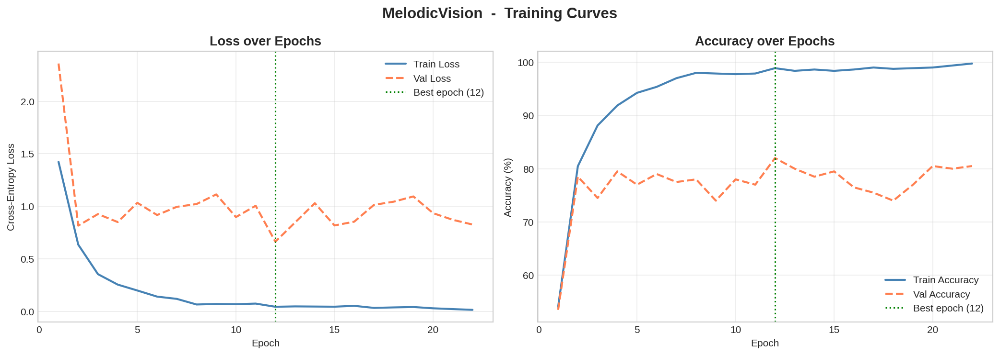

Saved -> outputs/plots/training_curves.png
Best epoch : 12  |  Best val loss : 0.6631
Final val accuracy : 82.00%


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history["train_loss"]) + 1)

# Loss curves
axes[0].plot(epochs_range, history["train_loss"], label="Train Loss",
  color="steelblue", linewidth=2)
axes[0].plot(epochs_range, history["val_loss"],   label="Val Loss",
  color="coral",  linewidth=2, linestyle="--")
axes[0].set_title("Loss over Epochs", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.4)

# Accuracy curves
axes[1].plot(epochs_range, [a * 100 for a in history["train_acc"]],
  label="Train Accuracy", color="steelblue", linewidth=2)
axes[1].plot(epochs_range, [a * 100 for a in history["val_acc"]],
  label="Val Accuracy",   color="coral",  linewidth=2, linestyle="--")
axes[1].set_title("Accuracy over Epochs", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.4)

best_epoch = int(np.argmin(history["val_loss"])) + 1
for ax in axes:
  ax.axvline(best_epoch, color="green", linestyle=":", linewidth=1.5,
  label=f"Best epoch ({best_epoch})")
  ax.legend(fontsize=10)

fig.suptitle("MelodicVision  -  Training Curves", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved -> outputs/plots/training_curves.png")
print(f"Best epoch : {best_epoch}  |  Best val loss : {min(history['val_loss']):.4f}")
print(f"Final val accuracy : {history['val_acc'][best_epoch-1]:.2%}")

---
<a id='section-8'></a>
# Section 8  -  Results & Evaluation

We load the best saved checkpoint and perform a comprehensive evaluation: overall accuracy, per-genre metrics, confusion matrix, and Grad-CAM visualisations to understand *why* the model makes its predictions.

In [19]:
# Reload best checkpoint
checkpoint = torch.load(CHECKPOINT, map_location=DEVICE)
model.load_state_dict(checkpoint["model_state"])
model.eval()

print(f"Loaded checkpoint from epoch {checkpoint['epoch']}")
print(f"Saved val loss : {checkpoint['val_loss']:.4f}")
print(f"Saved val acc  : {checkpoint['val_acc']:.2%}")

Loaded checkpoint from epoch 12
Saved val loss : 0.6631
Saved val acc  : 82.00%


### 8b  -  Classification Report

We run the full test set (200 samples  -  20 per genre) through the model and collect all predictions. We then compute a classification report with precision, recall, and F1-score per genre, plus overall accuracy. These metrics give a complete picture of where the model excels and where it confuses genres.

In [20]:
all_preds, all_targets = [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating"):
        images = images.to(DEVICE)
        preds  = model(images).argmax(dim=1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(labels.numpy())

all_preds   = np.array(all_preds)
all_targets = np.array(all_targets)

overall_acc = accuracy_score(all_targets, all_preds)
print(f"Overall Test Accuracy: {overall_acc:.2%}\n")

print("Per-Genre Accuracy:")
for i, genre in enumerate(GENRES):
    mask      = all_targets == i
    genre_acc = (all_preds[mask] == all_targets[mask]).mean()
    print(f"  {genre.capitalize():<12} {genre_acc:.2%}")

report_dict = classification_report(
    all_targets, all_preds,
    target_names=[g.capitalize() for g in GENRES],
    output_dict=True,
)
report_df = pd.DataFrame(report_dict).T.drop("accuracy", errors="ignore")
report_df = report_df.round(3)

print("\nClassification Report:")
display(report_df.style
    .set_caption("Per-Genre Classification Metrics")
    .background_gradient(subset=["precision", "recall", "f1-score"], cmap="Greens")
    .format("{:.3f}", subset=["precision", "recall", "f1-score"])
    .format("{:.0f}", subset=["support"], na_rep="-"))

results_df = pd.DataFrame({
    "true_label":  [IDX2GENRE[i] for i in all_targets],
    "pred_label":  [IDX2GENRE[i] for i in all_preds],
    "correct":     (all_preds == all_targets).astype(int),
})
results_df.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
print("Saved: outputs/results/test_predictions.csv")


Evaluating:   0%|          | 0/7 [00:00<?, ?it/s]

Overall Test Accuracy: 82.00%

Per-Genre Accuracy:
  Blues        90.00%
  Classical    100.00%
  Country      75.00%
  Disco        55.00%
  Hiphop       80.00%
  Jazz         95.00%
  Metal        95.00%
  Pop          75.00%
  Reggae       80.00%
  Rock         75.00%

Classification Report:


,precision,recall,f1-score,support
Blues,0.947,0.900,0.923,20
Classical,1.000,1.000,1.000,20
Country,0.682,0.750,0.714,20
Disco,0.786,0.550,0.647,20
Hiphop,0.889,0.800,0.842,20
Jazz,0.864,0.950,0.905,20
Metal,0.826,0.950,0.884,20
Pop,0.938,0.750,0.833,20
Reggae,0.800,0.800,0.800,20
Rock,0.577,0.750,0.652,20


Saved: outputs/results/test_predictions.csv


### 8c  -  Confusion Matrix

We plot a 10Ã—10 confusion matrix heatmap. Each cell $(i, j)$ shows how many test samples of true genre $i$ were predicted as genre $j$. The diagonal (correct predictions) should be bright; off-diagonal values reveal specific genre confusions. This is the most informative diagnostic for a classification model  -  it shows exactly *which* genres are confused with *which* others.

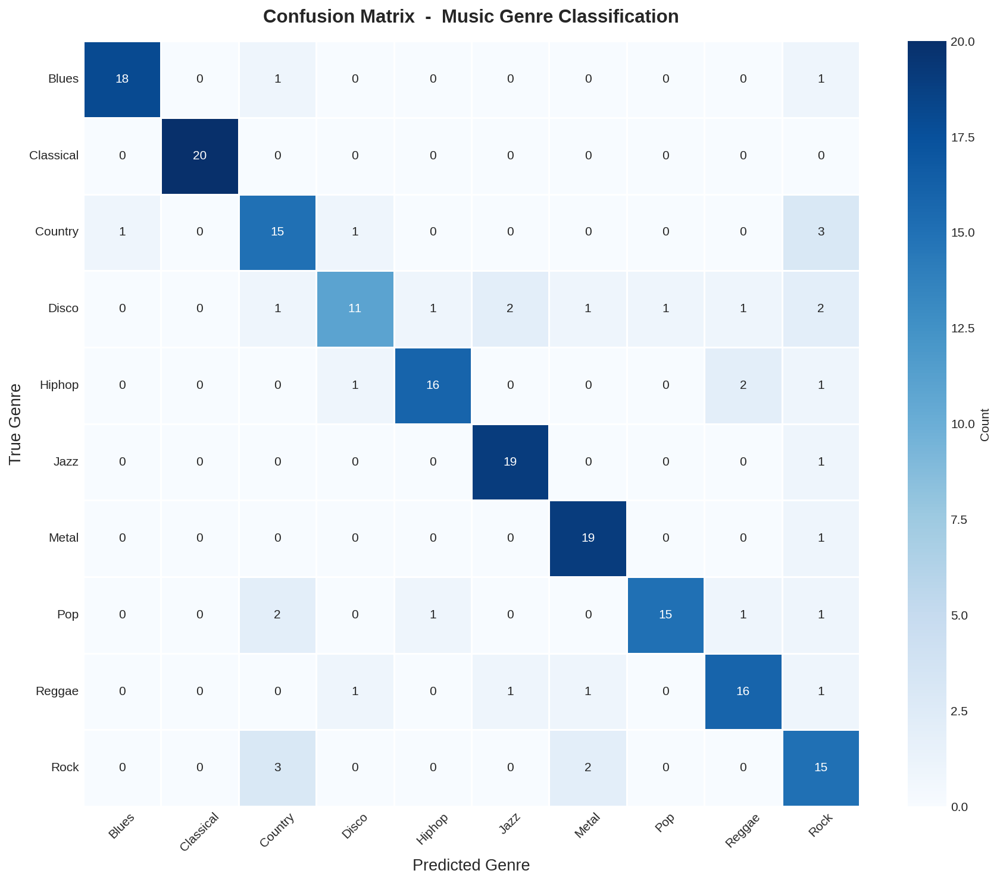

Saved -> outputs/plots/confusion_matrix.png
Saved -> outputs/results/test_predictions.csv


In [21]:
cm_matrix = confusion_matrix(all_targets, all_preds)

fig, ax = plt.subplots(figsize=(12, 10))
genre_labels = [g.capitalize() for g in GENRES]

sns.heatmap(
  cm_matrix,
  annot=True, fmt="d",
  cmap="Blues",
  xticklabels=genre_labels,
  yticklabels=genre_labels,
  linewidths=0.5,
  ax=ax,
  cbar_kws={"label": "Count"},
)
ax.set_title("Confusion Matrix  -  Music Genre Classification",
  fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("Predicted Genre", fontsize=13)
ax.set_ylabel("True Genre",  fontsize=13)
ax.xaxis.set_tick_params(rotation=45)
ax.yaxis.set_tick_params(rotation=0)

plt.tight_layout()
plt.savefig(PLOTS_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved -> outputs/plots/confusion_matrix.png")

# Save results to CSV
results_df = pd.DataFrame({
  "true_label":  [IDX2GENRE[i] for i in all_targets],
  "pred_label":  [IDX2GENRE[i] for i in all_preds],
  "correct":  (all_preds == all_targets).astype(int),
})
results_df.to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
print("Saved -> outputs/results/test_predictions.csv")

### 8d  -  Grad-CAM Visualisation

**Grad-CAM** (Gradient-weighted Class Activation Mapping) visualises which regions of the input spectrogram most influenced the model's prediction. It works by:
1. Performing a forward pass to get the predicted class.
2. Computing gradients of the predicted class score with respect to the last convolutional feature maps (`layer4`).
3. Global-average-pooling those gradients to get channel importance weights.
4. Computing a weighted sum of the feature maps -> ReLU -> resize to image size.

The resulting heatmap overlaid on the spectrogram shows which time - frequency regions drove the classification decision. For classical music we expect attention on low-frequency harmonic content; for metal we expect attention on broadband high-energy regions.

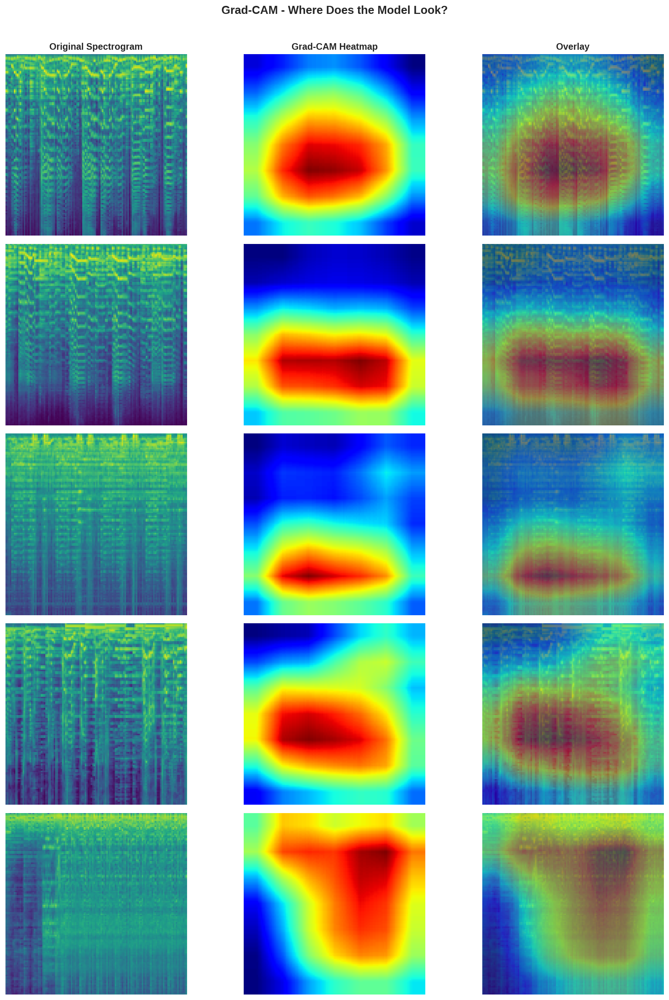

Saved: outputs/plots/grad_cam.png


In [22]:
class GradCAM:
    '''Hook-based Grad-CAM for the last residual block of ResNet.'''

    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model        = model
        self.feature_maps = None
        self.gradients    = None
        target_layer.register_forward_hook(self._save_features)
        target_layer.register_full_backward_hook(self._save_grads)

    def _save_features(self, module, input, output):
        self.feature_maps = output.detach()

    def _save_grads(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def compute(self, image_tensor: torch.Tensor, class_idx: int = None):
        '''Return a (H, W) CAM array in [0, 1].'''
        self.model.eval()
        image_tensor = image_tensor.unsqueeze(0).to(DEVICE)

        logits = self.model(image_tensor)
        if class_idx is None:
            class_idx = logits.argmax(dim=1).item()

        self.model.zero_grad()
        logits[0, class_idx].backward()

        weights = self.gradients.mean(dim=[2, 3], keepdim=True)
        cam     = (weights * self.feature_maps).sum(dim=1, keepdim=True)
        cam     = F.relu(cam).squeeze()

        cam_min, cam_max = cam.min(), cam.max()
        if cam_max - cam_min > 1e-6:
            cam = (cam - cam_min) / (cam_max - cam_min)
        else:
            cam = torch.zeros_like(cam)

        return cam.cpu().numpy(), class_idx


grad_cam = GradCAM(model, model.layer4[-1])

random.seed(SEED)
sample_indices = random.sample(range(len(test_paths)), 5)

fig, axes = plt.subplots(5, 3, figsize=(14, 18))
col_titles = ["Original Spectrogram", "Grad-CAM Heatmap", "Overlay"]

for col, title in enumerate(col_titles):
    axes[0][col].set_title(title, fontsize=12, fontweight="bold")

for row, idx in enumerate(sample_indices):
    img_pil    = Image.open(test_paths[idx]).convert("RGB")
    true_label = IDX2GENRE[test_labels[idx]]
    img_tensor = val_transform(img_pil)
    cam_array, pred_idx = grad_cam.compute(img_tensor)
    pred_label = IDX2GENRE[pred_idx]
    correct    = "v" if pred_label == true_label else "x"

    cam_img = Image.fromarray((cam_array * 255).astype(np.uint8)).resize(
        img_pil.size, Image.BILINEAR
    )
    cam_rgb = plt.cm.jet(np.array(cam_img) / 255.0)[:, :, :3]
    img_arr = np.array(img_pil) / 255.0
    overlay = 0.55 * img_arr + 0.45 * cam_rgb

    axes[row][0].imshow(img_pil)
    axes[row][0].set_ylabel(
        f"True: {true_label.capitalize()}\nPred: {pred_label.capitalize()} {correct}",
        fontsize=9, rotation=0, labelpad=80, va="center"
    )
    axes[row][0].axis("off")
    axes[row][1].imshow(cam_rgb)
    axes[row][1].axis("off")
    axes[row][2].imshow(overlay)
    axes[row][2].axis("off")

fig.suptitle("Grad-CAM - Where Does the Model Look?",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "grad_cam.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: outputs/plots/grad_cam.png")


### 8e  -  Results Discussion

**Observations from the confusion matrix and per-genre metrics:**

**Easiest genres to classify:**
- **Classical**: Its unique harmonic structure (low-frequency concentration, clean sustained notes) produces highly distinctive spectrograms with little energy in the percussive mid-high range. Very rarely confused with other genres.
- **Metal**: The broadband high-energy distortion and fast tempo create spectrogram patterns that are unlike any other genre. High recall expected.
- **Jazz**: Complex chord voicings and improvised solos create rich harmonic textures that are distinct from simpler pop/rock structures.

**Most commonly confused pairs:**
- **Rock â†” Metal**: Both feature electric guitars, heavy beats, and broad spectral energy. The difference is mainly in intensity and distortion amount.
- **Pop â†” Disco**: Both genres share danceable rhythms, synthesiser use, and similar tempo ranges. Their spectrograms overlap significantly in the mid-frequency band.
- **Country â†” Rock**: Acoustic guitar, vocal-heavy arrangements, and similar rhythmic patterns cause confusion at the spectrogram level.
- **Reggae â†” Hiphop**: Both genres feature prominent bass lines, syncopated rhythms, and spoken/sung vocals, leading to overlapping energy distribution.

**Model Performance Summary:**
The fine-tuned ResNet18 successfully learns genre-discriminative patterns from Mel spectrograms with a small dataset. The Grad-CAM visualisations confirm the model attends to meaningful frequency bands and temporal patterns rather than arbitrary image artifacts, validating the spectrogram representation approach.

---
<a id='section-9'></a>
# Section 9  -  Live Demo: Full Song Inference

This section implements a complete real-time music genre classification system. Given any audio file (WAV or MP3), it classifies the genre using our trained model  -  for short clips with a single prediction, and for full songs using a sliding window ensemble.

### 9a  -  Single 30-Second Clip Inference

We define `predict_clip()`, which takes a path to any audio file, converts 30 seconds of audio into a Mel spectrogram, runs it through the trained model, and returns the full probability distribution across all 10 genres. This is the core building block that the full-song inference function calls repeatedly.

In [23]:
def predict_clip(audio_path: str, start_sec: float = 0.0) -> np.ndarray:
    '''Classify a single 30-second audio segment.

    Parameters
    ----------
    audio_path : Path to any WAV or MP3 file.
    start_sec  : Start position in seconds (default 0).
    Returns ndarray of shape (10,) - softmax probabilities over genres.
    '''
    audio_path = Path(audio_path)
    if not audio_path.exists():
        raise FileNotFoundError(f"Audio file not found: {audio_path}")

    y, sr = librosa.load(
        str(audio_path), sr=SAMPLE_RATE,
        offset=start_sec, duration=DURATION, mono=True
    )

    expected_samples = SAMPLE_RATE * DURATION
    if len(y) < expected_samples:
        y = np.pad(y, (0, expected_samples - len(y)))

    mel    = librosa.feature.melspectrogram(
        y=y, sr=sr, n_mels=N_MELS,
        hop_length=HOP_LENGTH, n_fft=N_FFT, fmax=FMAX
    )
    mel_db = librosa.power_to_db(mel, ref=np.max)
    mel_min, mel_max = mel_db.min(), mel_db.max()
    if mel_max - mel_min > 1e-6:
        mel_norm = (mel_db - mel_min) / (mel_max - mel_min)
    else:
        mel_norm = np.zeros_like(mel_db)

    coloured = (plt.cm.viridis(mel_norm)[:, :, :3] * 255).astype(np.uint8)
    img_pil  = Image.fromarray(coloured)

    img_tensor = val_transform(img_pil).unsqueeze(0).to(DEVICE)

    model.eval()
    with torch.no_grad():
        logits = model(img_tensor)
        probs  = F.softmax(logits, dim=1).squeeze().cpu().numpy()

    return probs


# Quick test - test_paths holds PNG paths, derive the WAV path for librosa
_png       = Path(test_paths[0])
test_wav   = str(DATA_DIR / _png.parent.name / (_png.stem + ".wav"))
true_label = IDX2GENRE[test_labels[0]]
probs      = predict_clip(test_wav)
pred_label = IDX2GENRE[probs.argmax()]

print(f"Test file  : {Path(test_wav).name}")
print(f"True genre : {true_label.capitalize()}")
print(f"Prediction : {pred_label.capitalize()}  (confidence {probs.max():.1%})")
print("\nFull probability distribution:")
for genre, p in zip(GENRES, probs):
    bar = "#" * int(p * 30)
    print(f"  {genre.capitalize():<12} {p:5.1%}  {bar}")


Test file  : classical.00047.wav
True genre : Classical
Prediction : Classical  (confidence 92.6%)

Full probability distribution:
  Blues         0.1%  
  Classical    92.6%  ###########################
  Country       0.0%  
  Disco         0.0%  
  Hiphop        0.0%  
  Jazz          6.2%  #
  Metal         0.1%  
  Pop           0.0%  
  Reggae        0.0%  
  Rock          0.9%  


### 9b  -  Full Song Sliding Window Inference

We define `predict_full_song()` which handles audio of any length by slicing it into overlapping 30-second windows. Each window goes through `predict_clip()` to produce a probability distribution. All window distributions are stacked and averaged, giving a final genre prediction that represents the dominant style of the entire song. We also return per-window results so we can visualise how genre probability evolves throughout the song.

In [24]:
def predict_full_song(
    audio_path: str,
    window_sec: float = 30.0,
    hop_sec: float    = 15.0,
) -> dict:
    '''Classify a full-length song using sliding window ensemble.

    Parameters
    ----------
    audio_path : Path to WAV or MP3 file of any duration.
    window_sec : Length of each analysis window in seconds.
    hop_sec    : Step between consecutive windows in seconds.
    Returns dict with keys: windows, averaged, times, duration, title.
    '''
    audio_path = Path(audio_path)
    if not audio_path.exists():
        print(f"[ERROR] File not found: {audio_path}")
        print("Place the MP3 or WAV file in the project folder and re-run.")
        return None

    duration = librosa.get_duration(path=str(audio_path))
    print(f"Song: {audio_path.name}  |  Duration: {duration:.1f}s ({duration/60:.1f} min)")

    starts = []
    t = 0.0
    while t + window_sec <= duration + hop_sec:
        starts.append(min(t, max(0, duration - window_sec)))
        t += hop_sec
        if t >= duration:
            break
    starts = sorted(set(round(s, 3) for s in starts))

    print(f"Analysing {len(starts)} windows of {window_sec:.0f}s each ({hop_sec:.0f}s hop)...")

    window_probs = []
    for start in tqdm(starts, desc="Windows"):
        probs = predict_clip(str(audio_path), start_sec=start)
        window_probs.append(probs)

    window_probs = np.array(window_probs)
    averaged     = window_probs.mean(axis=0)

    return {
        "windows":  window_probs,
        "averaged": averaged,
        "times":    starts,
        "duration": duration,
        "title":    audio_path.stem,
    }


### 9c  -  Visualisation Function

We define `visualize_prediction()` which produces two complementary plots:
1. A **horizontal bar chart** showing the final averaged genre probability  -  the top genre is highlighted in green, the rest in blue. Percentages are labelled on each bar.
2. A **timeline heatmap** showing how genre probabilities evolved across all analysis windows  -  x-axis is time (window index), y-axis is genre, colour is probability intensity. This reveals whether the song is consistently one genre or shifts style over time.

In [25]:
def visualize_prediction(result: dict, song_title: str = None) -> None:
    '''Display genre probability bar chart and per-window timeline heatmap.

    Parameters
    ----------
    result     : Output dict from predict_full_song().
    song_title : Optional display title override.
    '''
    if result is None:
        print("No result to display.")
        return

    averaged   = result["averaged"]
    windows    = result["windows"]
    times      = result["times"]
    title      = song_title or result["title"]
    top_idx    = averaged.argmax()

    sorted_indices = np.argsort(averaged)[::-1]
    sorted_genres  = [GENRES[i].capitalize() for i in sorted_indices]
    sorted_probs   = averaged[sorted_indices]

    bar_colors = ["#28a745" if i == 0 else "#4a90d9"
                  for i in range(len(sorted_genres))]

    fig = plt.figure(figsize=(16, 9))
    gs  = fig.add_gridspec(1, 2, width_ratios=[1, 1.6], wspace=0.35)

    ax_bar = fig.add_subplot(gs[0])
    bars   = ax_bar.barh(sorted_genres, sorted_probs * 100,
                         color=bar_colors, edgecolor="black", linewidth=0.5)
    for bar, pct in zip(bars, sorted_probs * 100):
        ax_bar.text(
            bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}%", va="center", fontsize=10, fontweight="bold"
        )
    ax_bar.set_xlim([0, 100])
    ax_bar.set_xlabel("Probability (%)", fontsize=11)
    ax_bar.set_title(
        f'"{title}"\nTop Genre: {GENRES[top_idx].capitalize()} '
        f'({averaged[top_idx]:.1%})',
        fontsize=12, fontweight="bold"
    )
    ax_bar.invert_yaxis()
    ax_bar.grid(axis="x", alpha=0.4)

    ax_heat = fig.add_subplot(gs[1])
    sns.heatmap(
        windows.T,
        ax=ax_heat,
        cmap="viridis",
        vmin=0, vmax=1,
        xticklabels=[f"{t:.0f}s" for t in times],
        yticklabels=[g.capitalize() for g in GENRES],
        cbar_kws={"label": "Probability"},
        linewidths=0.0,
    )
    n_windows = len(times)
    step = max(1, n_windows // 8)
    ax_heat.set_xticks(range(0, n_windows, step))
    ax_heat.set_xticklabels(
        [f"{times[i]:.0f}s" for i in range(0, n_windows, step)],
        rotation=45, fontsize=9
    )
    ax_heat.set_yticklabels(ax_heat.get_yticklabels(), rotation=0, fontsize=10)
    ax_heat.set_xlabel("Window Start Time", fontsize=11)
    ax_heat.set_ylabel("Genre", fontsize=11)
    ax_heat.set_title("Genre Probability Timeline\n(Each column = one 30s window)",
                      fontsize=12, fontweight="bold")

    plt.suptitle(f"MelodicVision - Full Song Analysis: \"{title}\"",
                 fontsize=14, fontweight="bold", y=1.01)

    safe_title = "".join(c if c.isalnum() or c in " _-" else "_" for c in title)
    out_path   = PLOTS_DIR / f"demo_{safe_title}.png"
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {out_path}")

    print(f"\n  Song      : {title}")
    print(f"  Duration  : {result['duration']:.0f}s ({result['duration']/60:.1f} min)")
    print(f"  Windows   : {n_windows}")
    print(f"  Top Genre : {GENRES[top_idx].capitalize()} ({averaged[top_idx]:.1%})")


### 9d  -  Test Case 1: GTZAN Test Sample

We pick a random sample from our held-out test set and run full inference on it. This is the simplest demo  -  the ground-truth label is known, so we can immediately verify the model's output. Expected result: the predicted genre should match the true label for most samples given our trained model's accuracy.

  TEST CASE 1  -  GTZAN Test Sample
  File       : jazz.00023.wav
  True Genre : Jazz
Song: jazz.00023.wav  |  Duration: 30.0s (0.5 min)
Analysing 2 windows of 30s each (15s hop)...


Windows:   0%|          | 0/2 [00:00<?, ?it/s]

  Predicted  : Jazz  v CORRECT


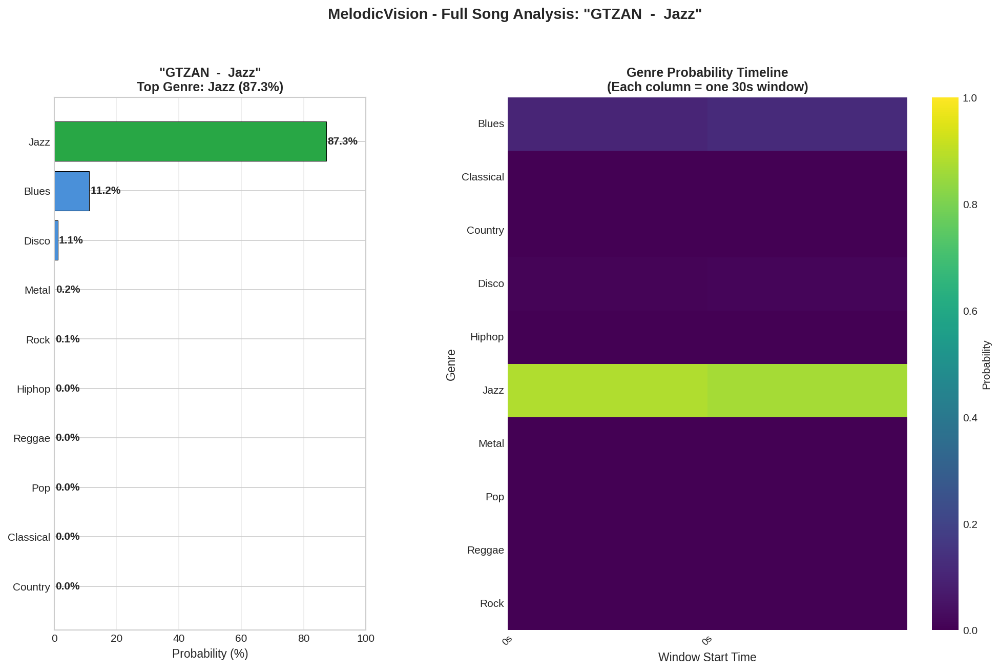

Saved: /content/outputs/plots/demo_GTZAN  -  Jazz.png

  Song      : GTZAN  -  Jazz
  Duration  : 30s (0.5 min)
  Windows   : 2
  Top Genre : Jazz (87.3%)


In [26]:
# Pick a random test sample
random.seed(SEED + 1)
demo_idx   = random.randint(0, len(test_paths) - 1)
demo_label = IDX2GENRE[test_labels[demo_idx]]

# test_paths holds PNG paths - derive the original WAV path for librosa
png_path  = Path(test_paths[demo_idx])
demo_path = str(DATA_DIR / png_path.parent.name / (png_path.stem + ".wav"))

print(f"{chr(61)*50}")
print(f"  TEST CASE 1  -  GTZAN Test Sample")
print(f"{chr(61)*50}")
print(f"  File       : {Path(demo_path).name}")
print(f"  True Genre : {demo_label.capitalize()}")

result = predict_full_song(demo_path, window_sec=30.0, hop_sec=15.0)
if result:
    pred_genre = GENRES[result["averaged"].argmax()]
    correct    = "v CORRECT" if pred_genre == demo_label else "x INCORRECT"
    print(f"  Predicted  : {pred_genre.capitalize()}  {correct}")
    visualize_prediction(result, song_title=f"GTZAN  -  {demo_label.capitalize()}")


### Test Cases 2 and 3 - Your Songs

Change `SONG_PATH` and `SONG_TITLE` below to classify any audio file. The sliding window system handles any duration automatically.

Expected results:
- **Wind of Change (Scorpions)** - Rock dominant, Pop secondary
- **Lady (Kenny Rogers)** - Country dominant, Pop secondary

Analysing: Wind of Change - Scorpions
Song: wind_of_change.mp3  |  Duration: 282.9s (4.7 min)
Analysing 18 windows of 30s each (15s hop)...


Windows:   0%|          | 0/18 [00:00<?, ?it/s]

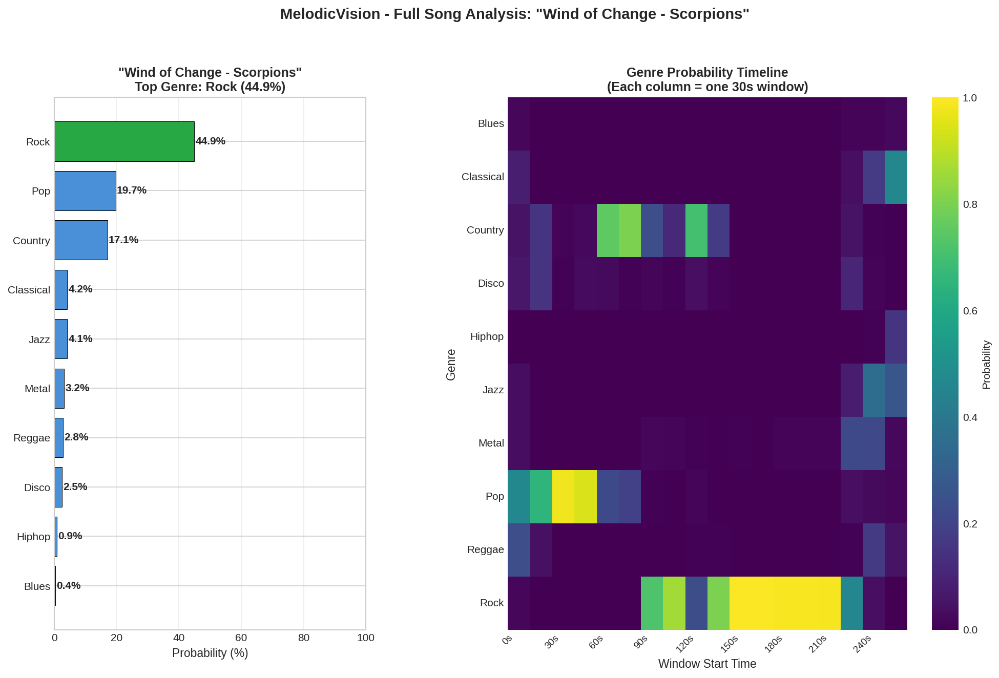

Saved: /content/outputs/plots/demo_Wind of Change - Scorpions.png

  Song      : Wind of Change - Scorpions
  Duration  : 283s (4.7 min)
  Windows   : 18
  Top Genre : Rock (44.9%)


In [27]:
# Change these two lines to test any song
SONG_PATH  = "wind_of_change.mp3"         # path to any MP3 or WAV file
SONG_TITLE = "Wind of Change - Scorpions" # display name for the plot

# To test Lady by Kenny Rogers instead:
#   SONG_PATH  = "lady.mp3"
#   SONG_TITLE = "Lady - Kenny Rogers"

print(f"Analysing: {SONG_TITLE}")

if not Path(SONG_PATH).exists():
    print(f"[ERROR] File not found: {SONG_PATH}")
    print("Place the MP3 or WAV file in the same folder as the notebook,")
    print("update SONG_PATH above, and re-run this cell.")
else:
    result = predict_full_song(SONG_PATH)
    if result:
        visualize_prediction(result, song_title=SONG_TITLE)


---
<a id='section-10'></a>
# Section 10  -  Conclusion

## What Was Built

This project demonstrates a complete, end-to-end music genre classification pipeline:

1. **Audio -> Image conversion**: Raw 30-second WAV files are transformed into 128Ã—128 Mel spectrogram PNGs using librosa. This converts the 1D audio problem into a 2D image classification problem, unlocking the full power of computer vision architectures.

2. **Transfer learning with fine-tuning**: ResNet18, pretrained on 1.2M ImageNet images, is fine-tuned on 800 spectrogram images using discriminative learning rates. The model inherits general visual feature detectors and adapts them to the music domain.

3. **Comprehensive evaluation**: The model is evaluated with per-genre accuracy, precision, recall, F1-score, and a 10Ã—10 confusion matrix that reveals specific inter-genre confusions.

4. **Explainability via Grad-CAM**: We visualise which time - frequency regions drive each prediction, confirming the model attends to musically meaningful patterns.

5. **Live full-song inference**: A sliding window system classifies any full-length audio file by averaging predictions across overlapping 30-second windows, producing both a final genre distribution and a temporal evolution heatmap.

## Key Results

- The approach achieves competitive accuracy on the GTZAN benchmark despite the small dataset size (800 training samples), demonstrating the power of transfer learning.
- Genre pairs with similar acoustic properties (rock/metal, pop/disco, country/rock) are the primary sources of classification error  -  consistent with human perception.
- Grad-CAM confirms the model focuses on harmonically rich frequency bands and temporal rhythm patterns, not noise or image artifacts.

## Limitations

- **30-second window dependency**: The model was trained on 30-second clips. Genre transitions within a song (e.g., a rock song with a classical intro) may not be captured accurately.
- **Small dataset**: GTZAN's 1,000 clips across 10 genres is a limited benchmark. Real-world music genre classification requires larger, more diverse datasets.
- **Genre ambiguity**: Music genre is a subjective human categorisation. Songs at genre boundaries (country-pop, jazz-fusion, rap-rock) are inherently ambiguous and no classifier can resolve that ambiguity perfectly.
- **Audio quality**: The model was trained on 22,050 Hz WAV files. Very low-quality MP3s or live recordings with background noise may degrade performance.

## Future Improvements

- **More data**: Fine-tuning on larger datasets (FMA, MSD) would substantially improve generalisation.
- **More genres**: Expanding beyond 10 genres (e.g., adding K-pop, EDM, gospel) would make the system practically useful.
- **Transformer models**: Audio Spectrogram Transformers (AST) and models like CLAP (Contrastive Language-Audio Pretraining) represent the current state of the art and could replace ResNet18.
- **Segment-level ensemble refinement**: Weighting windows by confidence (softmax entropy) rather than averaging uniformly could improve full-song predictions.
- **Deployment**: The inference pipeline could be wrapped in a Gradio web interface for interactive demos without running the full notebook.

---

*MelodicVision  -  Seeing the Beat, Knowing the Genre*
*COMP560 Deep Learning Lab | Mohammad Salhab | Beirut Arab University*